In [19]:
%load_ext autoreload
%autoreload 2

import numpy as np
from polyergalio.models.model_loss import HuberLoss, MSELoss
from polyergalio.models.optimizers import Adam
from polyergalio.models.layers import (
    FullyConnectedLayer,
    DropoutLayer,
    NormalizeLayer,
    RMSNormLayer,
    FrequencyFFT,
    SpectreAttention,
    LatentExpand,
    SpectrePooledAttention,
    MixtureOfExperts,
    LatentStack, LatentSum
)
from polyergalio.encoders.audio_encoders import (AudioProcessor,
                                                 read_wav,
                                                 window_size_from_ms,
                                                 plot_waveform,
                                                 plot_spectrogram,
                                                 plot_window_spectra)
from polyergalio.profiling.profiling import Profiler
from polyergalio.models.embedding.positional import RopeEmbedding

import matplotlib.pyplot as plt

# MAX_POSSIBLE_WINDOWS = 2**10


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
# loading our audio files:
import os
WINDOW_LENGTH_MS = 2000
sample_rate, _ = read_wav(f"../data/ele_rumble_unit-01_2025-05-23_08_merged_t918.776-924.168_id-00011.wav", channel=0, standardize=False)
time_per_sample = 1000 / sample_rate
samples_per_window = window_size_from_ms(sample_rate, WINDOW_LENGTH_MS)
# samples_per_window = WINDOW_LENGTH_MS / time_per_sample
real_positive_fft_shape = (samples_per_window // 2) + 1

NUM_BANDS = 1000
max_frequency = 4000 * 2

all_windowed_data = []

all_filenames = os.listdir(f"../data/")
waveforms = []
for fn in all_filenames:
    if fn.endswith(".wav"):
        sample_rate, left = read_wav(f"../data/{fn}", channel=0, standardize=True)
        waveforms.append(left)
        try:
            _, right = read_wav(f"../data/{fn}", channel=1, standardize=True)
            waveforms.append(right)
        except Exception:
            pass

audio_enc = AudioProcessor(
    sample_rate=sample_rate,
    window_ms=WINDOW_LENGTH_MS,
    overlap_ratio=1 / 6,
    num_bands=NUM_BANDS,
    min_frequency=1,
    max_frequency=max_frequency,
    use_decibels=True,
    standardize=False,
)
audio_enc.fit(waveforms)
all_windowed_data = [audio_enc.encode(waveform)["bands"] for waveform in waveforms]

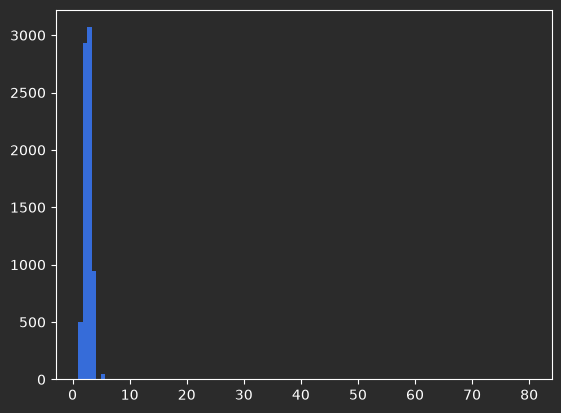

80


In [21]:
shapes = []
np.random.shuffle(all_windowed_data)

for windowed_data in all_windowed_data:
    shapes.append(windowed_data.shape[0])

plt.hist(np.clip(shapes, min=0, max=1000), bins=100)
plt.show()
print(np.max(shapes))

In [22]:
# MAX_POSSIBLE_WINDOWS should be optimized for specific lengths of FFT: closest to: (2**10 * N)
# MAX_POSSIBLE_WINDOWS = 2**10 * 1
MAX_POSSIBLE_WINDOWS = 100


# IF SPECTRAL:
# samples_per_window = samples_per_window // 2 + 1
samples_per_window = NUM_BANDS

# pad our sequences to max:
xs = np.zeros((len(all_windowed_data), MAX_POSSIBLE_WINDOWS, samples_per_window))
padding_mask = np.zeros((len(all_windowed_data), MAX_POSSIBLE_WINDOWS))
for idx, data in enumerate(all_windowed_data):
    l, n = data.shape
    l = min(l, MAX_POSSIBLE_WINDOWS)
    xs[idx, :l, :] = data[:l, ...]
    padding_mask[idx, :l] = 1

print(xs.shape)
print(padding_mask.shape)

(7504, 100, 1000)
(7504, 100)


In [23]:
xs = xs[padding_mask.astype("bool")]

In [24]:
print(xs.shape, padding_mask.shape)

(19994, 1000) (7504, 100)


In [25]:
from polyergalio.models.layers.autoencoder_layers import GMVAELayer, NVPVAELayer

In [26]:
from polyergalio.models.network import Network
from polyergalio.visuals.nnet_visuals import plot_network


# EMBEDDING_DIM = 1200
HIDDEN_DIM = 512
NUM_COMPONENTS = 5
lambda_exp = 0.5

DOWNSCALE = int(samples_per_window*.75)

# samples_per_window = the samples per window (final dimesion of xs)
print(samples_per_window)
print(MAX_POSSIBLE_WINDOWS)


net = Network(name="audio_encoder_decoder", input_shape=(samples_per_window,))
incoming = net.input
vae = net.connect(GMVAELayer(input_dimension=samples_per_window,
                             hidden_dimension=HIDDEN_DIM,
                             latent_dimension=16,
                             w_dimension=2,
                             prior_hidden_dimension=64,
                             num_components=NUM_COMPONENTS,
                             information_constraint=lambda_exp * np.log(NUM_COMPONENTS),
                             num_samples=1,
                             output_activation="linear"),
                  incoming,
                  name="vae")
net.output = vae


print("edges:")
for producer, consumer in net.edges():
    print(f"  {producer:10s} -> {consumer}")


1000
100
edges:
  input      -> vae



audio_encoder_decoder: 1 nodes, 1588588 parameters
  node  sources                    shape
  vae  input                      (1000,) <- output


<Axes: title={'center': 'audio_encoder_decoder'}>

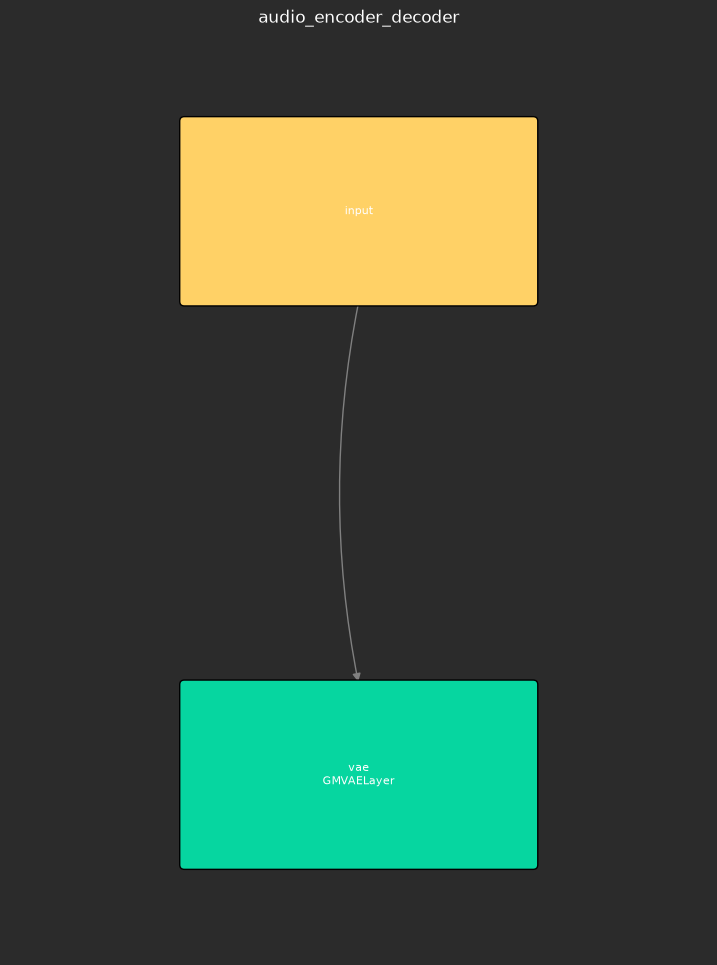

In [27]:

print()
print(net.summary())
plot_network(net)

In [28]:
profiler = Profiler()

net.eval()
with profiler:
    output = profiler.call(net.forward, xs[0:256, ...], label="eval_forward x5", num_loops=5)

net.train()
with profiler:
    output = profiler.call(net.forward, xs[0:256, ...], label="train_forward x5", num_loops=5)

print(profiler.summary())


label             calls   mean ms    min ms    max ms    self ms  self %  us/sample   net MB  peak MB   min MB   max MB
-----------------------------------------------------------------------------------------------------------------------
train_forward x5      5      3.43      3.00      4.31      17.16    57.2      13.41     2.25     4.79     3.17    11.31
eval_forward x5       5      2.57      2.41      2.97      12.83    42.8      10.03     0.41     3.24     3.24     3.24


In [29]:
net

Network(1 nodes, 1588588 parameters)

In [30]:
idx_shuffler = np.arange(len(xs))
np.random.shuffle(idx_shuffler)
holdout = xs[idx_shuffler[:1000]]
xs = xs[idx_shuffler[1000:]]

Automatic pdb calling has been turned ON
EPOCH 0, lr decaying to 0.001
step 0 mean reconstruction loss over last 40: 0.2162407361499091Reconstruction loss 0.20961859999220359


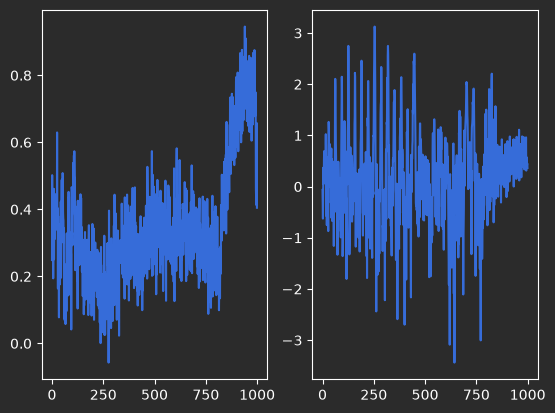

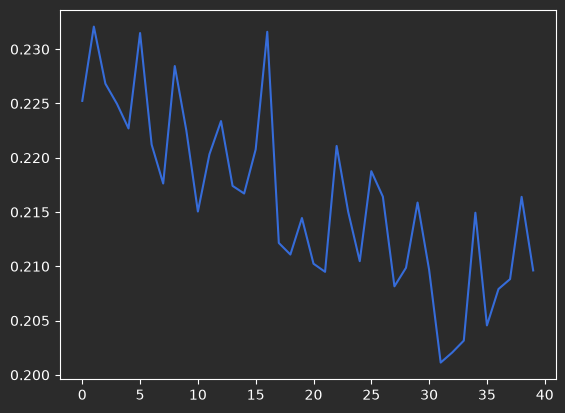

z prior:  0.9982878566372679
conditional prior:  15.654840388602729
w prior:  1.1384492992194435
recognize variance 0.4417380618361382
step 148  reconstruction loss 0.19837564600226892


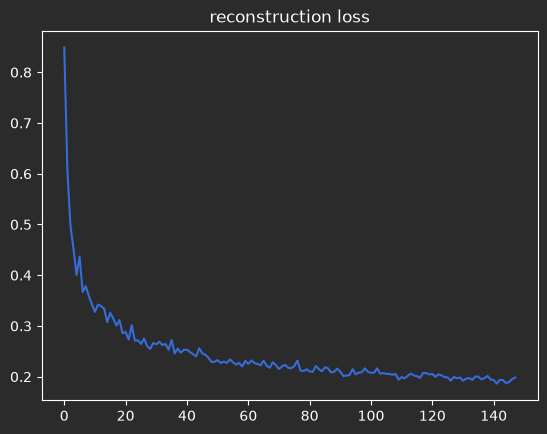

EPOCH 1, lr decaying to 0.001
step 0 mean reconstruction loss over last 40: 0.17853943208256848Reconstruction loss 0.17623982613530317


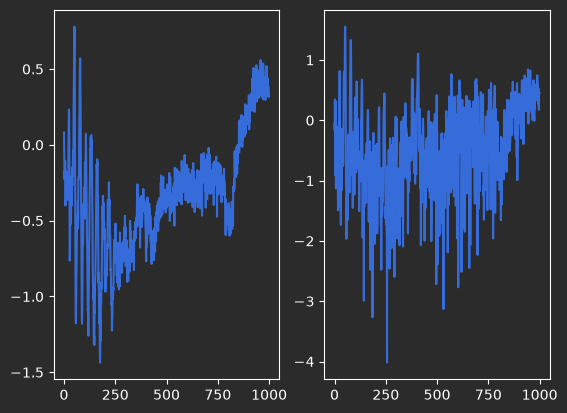

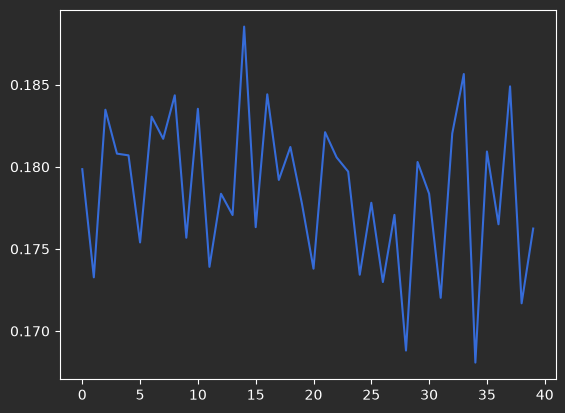

z prior:  1.207009729663351
conditional prior:  19.207442197581237
w prior:  1.581619350330628
recognize variance 0.7902317107403475
step 148  reconstruction loss 0.1661715690701502


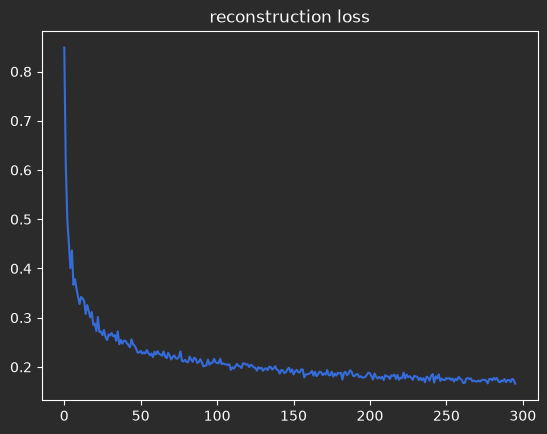

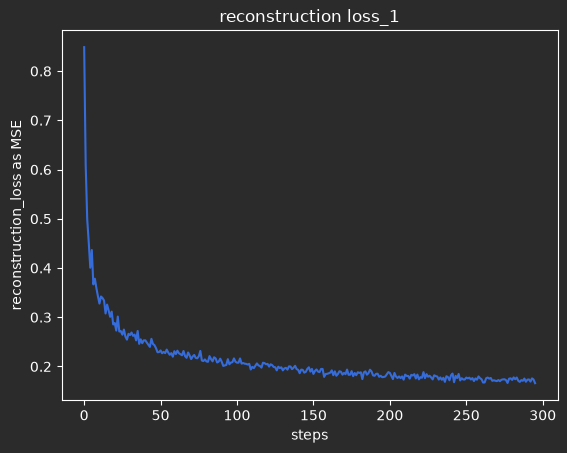

In [31]:
# AND this is how we train:
%pdb on
BATCH_SIZE = 128
EPOCHS = 2
LR = 1e-3
DIVI = 100
NUM_SAMPLES = 1

loss = HuberLoss(delta=1.12)
optimizer = Adam(LR)


idx_shuffler = np.arange(len(xs))
all_losses = []
verbose = True

for epoch in range(0, EPOCHS):
    NUM_SAMPLES = min(NUM_SAMPLES, 30)
    net.train()
    print(f'EPOCH {epoch}, lr decaying to {LR}')
    np.random.shuffle(idx_shuffler)

    net["vae"].num_samples = NUM_SAMPLES
    # decay rate for LR
    optimizer.learning_rate = LR * (0.96 ** epoch)

    _permuted_xs = xs[idx_shuffler, ...]
    for step_i, batch_st in enumerate(range(0, len(xs), BATCH_SIZE)):
        verbose = (step_i + 1) % DIVI == 0
        _xs = _permuted_xs[batch_st:batch_st+BATCH_SIZE, :]

        # lazy workaround -- continue back to steps/batch if we don't have enough samples left
        if _xs.shape[0] != BATCH_SIZE:
            continue

        for _ in range(1):
            x_prime = net.forward(_xs)
            reconstruction_loss = loss.forward(prediction=x_prime,
                                               targets=_xs)

            all_losses.append(reconstruction_loss.item())

            net.backward(loss.backward() * samples_per_window / (2 * max(reconstruction_loss, 1e-8)))
            optimizer.step(net)
            net.zero_gradients()

        if verbose:
            print(f"step {_} mean reconstruction loss over last 40: {np.mean(all_losses[-40:])}"
                  f"Reconstruction loss {reconstruction_loss}")
            sample = _xs[1]
            plt.figure()
            plt.subplot(1, 2, 1)
            plt.plot(x_prime[1, :])
            plt.subplot(1, 2, 2)
            plt.plot(_xs[1, :])
            plt.show()

            plt.plot(all_losses[-40:])
            plt.show()
            print("z prior: ", net["vae"].z_prior)
            print("conditional prior: ", net["vae"].conditional_prior)
            print("w prior: ", net["vae"].w_prior)
            vae = net["vae"]
            x_mean, *_ = vae.recognize(sample)
            print("recognize variance", x_mean.var(axis=0))

            net.serialize("elephant_gmvae_enc_dec_reconstruction.ergalio")

    print(f"step {step_i}  reconstruction loss {reconstruction_loss}")
    plt.plot(all_losses)
    plt.title("reconstruction loss")
    plt.show()
    net.serialize("elephant_gmvae_enc_dec_reconstruction.ergalio")
    NUM_SAMPLES *= 2
plt.figure()
plt.plot(all_losses)
plt.title(f"reconstruction loss_{epoch}")
plt.ylabel("reconstruction_loss as MSE")
plt.xlabel("steps")
plt.savefig(f"reconstruction loss_{epoch}.png")
plt.show()

windows per component [203 193 187 132 285]
mean confidence 0.8411993487957441
variance explained 0.5692975189806337


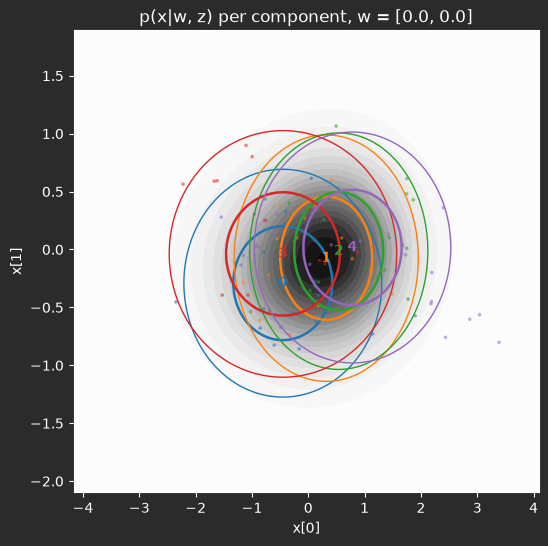

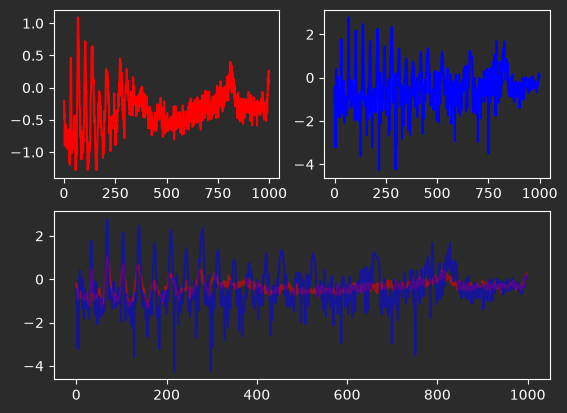

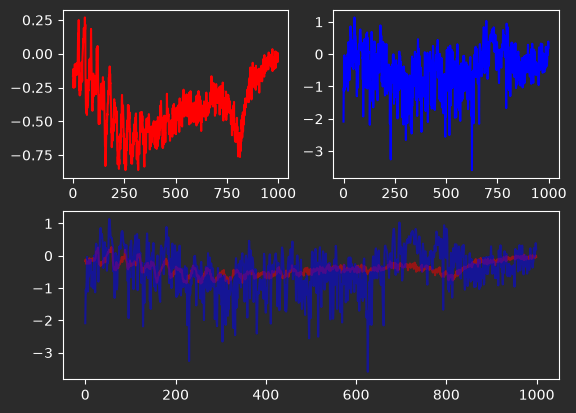

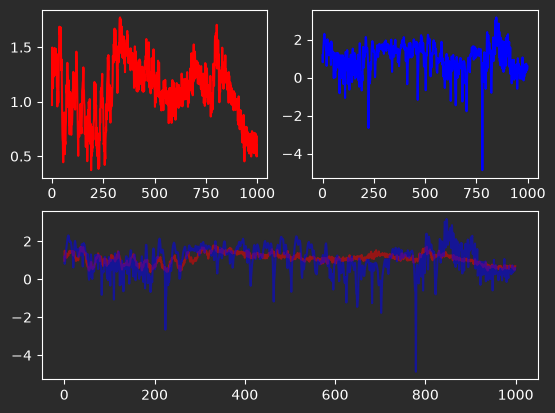

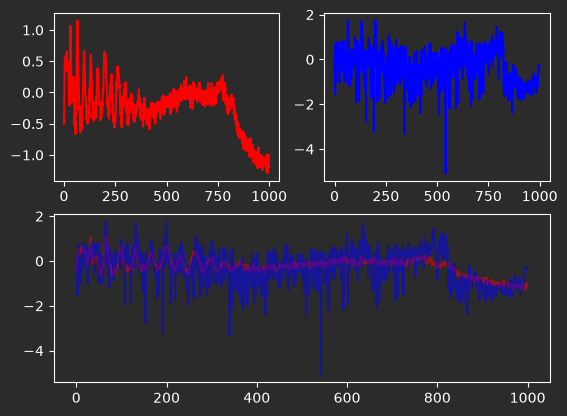

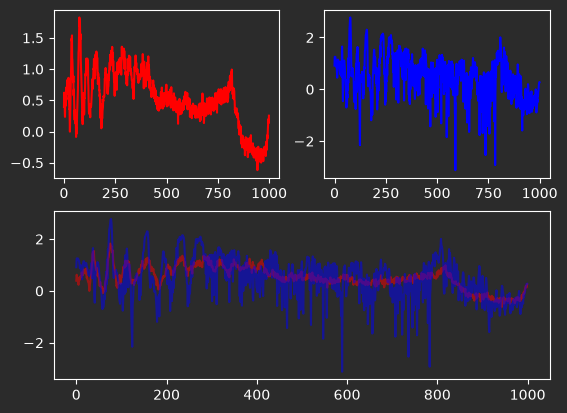

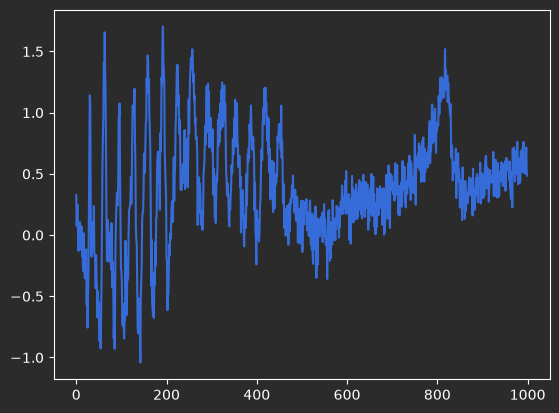

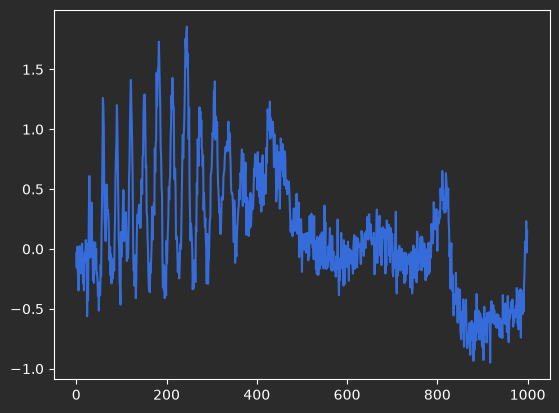

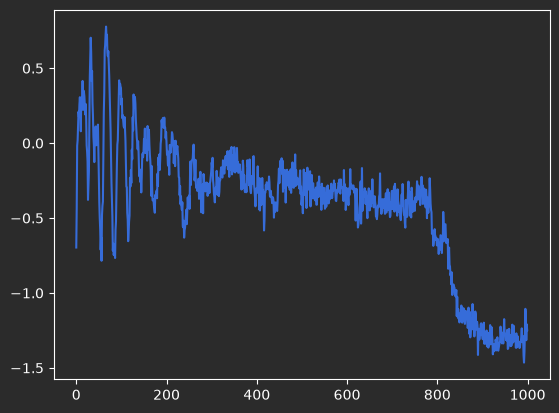

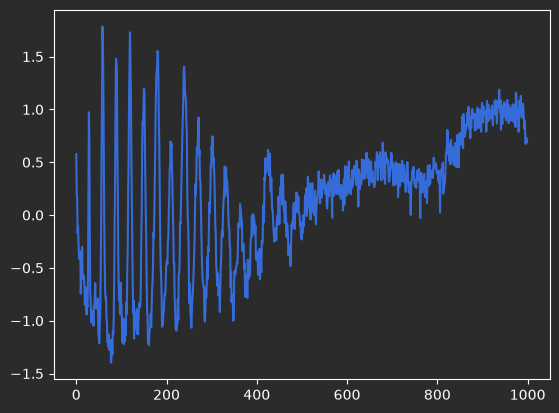

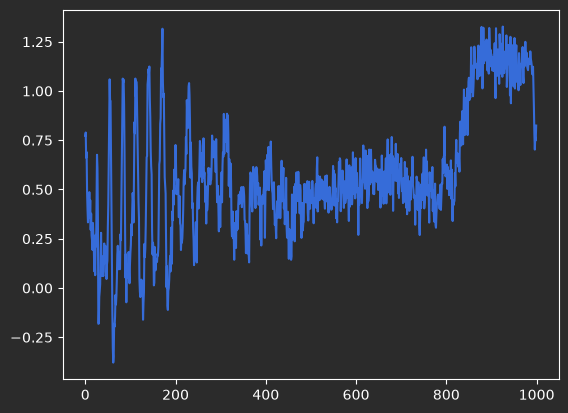

In [32]:
net.eval()
vae = net["vae"]
np.random.shuffle(holdout)

probabilities = vae.cluster(holdout)
components = probabilities.argmax(axis=1)
print("windows per component", np.bincount(components, minlength=vae.num_components))
print("mean confidence", probabilities.max(axis=1).mean())
print("variance explained", 1 - ((net.forward(holdout) - holdout) ** 2).mean() / holdout.var(axis=0).mean())

vae.plot_latent(holdout[::10], components[::10])
plt.show()

for idx in range(0, 5):
    pred = net.forward(holdout[idx])
    plt.figure()
    plt.subplot(2, 2, 1)
    plt.plot(pred, color="red")
    plt.subplot(2, 2, 2)
    plt.plot(holdout[idx], color="blue")
    plt.subplot(2, 2, (3,4))
    plt.plot(pred, color="red", alpha=0.5)
    plt.plot(holdout[idx], color="blue", alpha=0.5)
    plt.show()

for k in range(vae.num_components):
    generated = vae.generate(1, components=k)
    plt.plot(generated[0])
    plt.show()


In [33]:
x_mean, x_log_variance, w_mean, w_log_variance = vae.recognize(holdout)
means, log_variances = vae.component_parameters(w_mean)
separation = means.std(axis=1).mean(axis=-1) / np.exp(0.5 * log_variances).mean(axis=(1, 2))
print("avg separation ", separation.mean())
print("z_prior" , vae.z_prior)
print("information constraint ", vae.information_constraint)

avg separation  0.5830470116411579
z_prior 1.2329041610144595
information constraint  0.8047189562170501


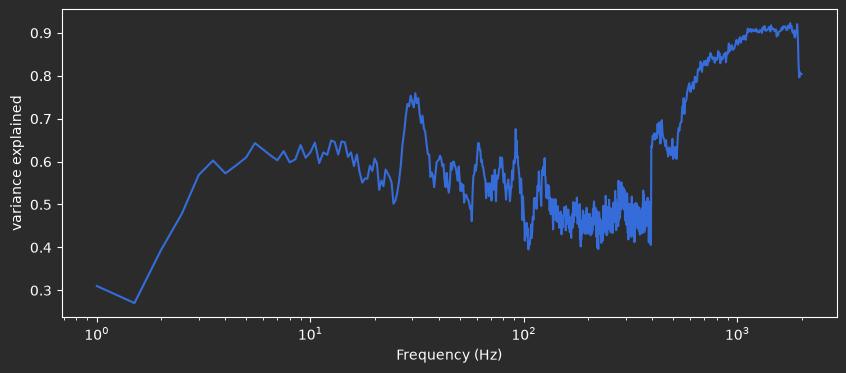

1 bin bands: n=786  mean R2=0.500
5 bin bands: n=1  mean R2=0.636
6 bin bands: n=10  mean R2=0.659
7 bin bands: n=19  mean R2=0.646
8 bin bands: n=16  mean R2=0.661
9 bin bands: n=15  mean R2=0.759
wide bands (>=20 bins): mean R2 0.8989192602811598


In [34]:
reconstruction = net.forward(holdout)
band_residual = ((reconstruction - holdout) ** 2).mean(axis=0)
band_r2 = 1 - band_residual / holdout.var(axis=0)
bins_per_band = (audio_enc.band_weights > 0).sum(axis=1)

plt.figure(figsize=(10, 4))
plt.semilogx(audio_enc.band_frequencies, band_r2)
plt.xlabel("Frequency (Hz)")
plt.ylabel("variance explained")
plt.show()

for width in np.unique(bins_per_band)[:6]:
    selected = bins_per_band == width
    print(f"{width} bin bands: n={selected.sum()}  mean R2={band_r2[selected].mean():.3f}")
print("wide bands (>=20 bins): mean R2", band_r2[bins_per_band >= 20].mean())

share of between-component variance that is overall level: 0.4384256056677749


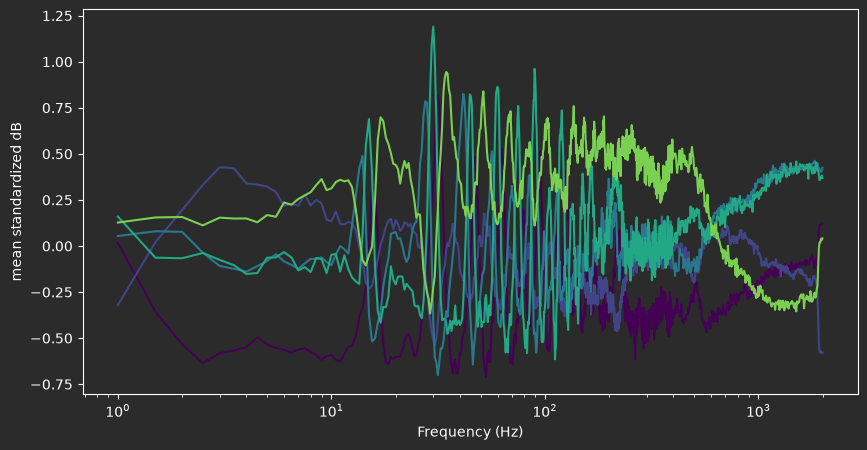

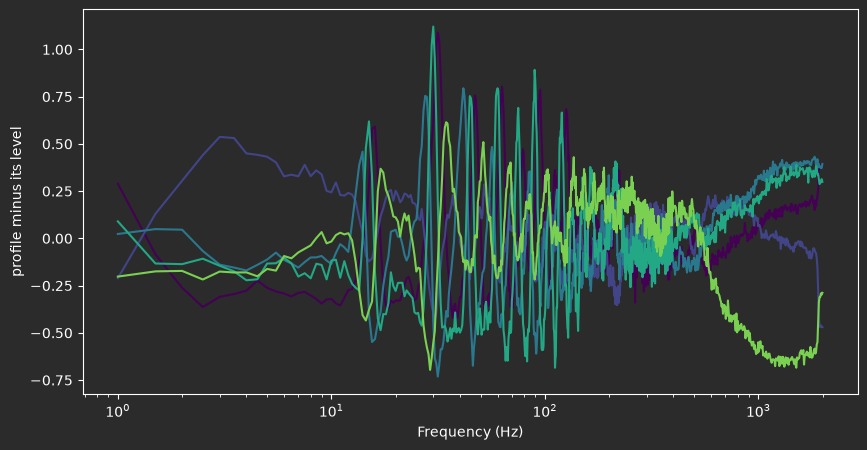

In [35]:
profiles = np.stack([holdout[components == k].mean(axis=0) for k in range(vae.num_components)])
level = profiles.mean(axis=1)
level_share = level.var() / profiles.var(axis=0).mean()
print("share of between-component variance that is overall level:", level_share)

order = np.argsort(level)
plt.figure(figsize=(10, 5))
for rank, k in enumerate(order):
    plt.semilogx(audio_enc.band_frequencies, profiles[k], color=plt.cm.viridis(rank / len(order)))
plt.xlabel("Frequency (Hz)")
plt.ylabel("mean standardized dB")
plt.show()

shape = profiles - level[:, None]
plt.figure(figsize=(10, 5))
for rank, k in enumerate(order):
    plt.semilogx(audio_enc.band_frequencies, shape[k], color=plt.cm.viridis(rank / len(order)))
plt.xlabel("Frequency (Hz)")
plt.ylabel("profile minus its level")
plt.show()